# IMC Prosperity 4 -- Tutorial Round 1: Complete Starter Guide

This notebook is a comprehensive walkthrough of everything you need to understand to write, test, and submit a trading algorithm for the IMC Prosperity 4 challenge. By the end you will:

1. **Understand the data** -- what every column in the provided CSVs means and how to explore it.
2. **Visualize price dynamics** -- see how each product behaves so you can pick the right strategy.
3. **Master the datamodel** -- know every class (`TradingState`, `OrderDepth`, `Order`, `Trade`, ...) inside-out.
4. **Understand the execution model** -- how the simulation loop works, how orders match, what position limits do, and how state persistence works.
5. **Build three strategies** -- from a do-nothing skeleton to a real market-taking algorithm.
6. **Backtest locally** -- replay historical data through your trader and measure PnL before you upload.

---

## Products in This Round

| Product | Description |
|---------|-------------|
| **EMERALDS** | A stable-value product that hovers around a known fair price. |
| **TOMATOES** | A trending product whose price drifts over time. |

---

# Section A: Understanding the Data

Two CSV files are provided for each sample day:

### 1. Prices CSV (`prices_round_0_day_-1.csv`)

This file contains one row **per product per timestamp**. Each row is a snapshot of the order book at that moment.

| Column | Meaning |
|--------|---------|
| `day` | Which sample day (-1, -2, etc.). Negative numbers = historical sample days. |
| `timestamp` | Simulation tick in milliseconds. Runs from 0 to 999,900 in steps of 100 (= 10,000 iterations). |
| `product` | The tradable product name (EMERALDS or TOMATOES in this round). |
| `bid_price_1` | **Best (highest) bid price** -- the highest price someone is willing to pay right now. |
| `bid_volume_1` | How many units are available at `bid_price_1`. |
| `bid_price_2`, `bid_volume_2` | Second-best bid level (lower price, more depth). |
| `bid_price_3`, `bid_volume_3` | Third-best bid level (may be NaN if only 2 levels exist). |
| `ask_price_1` | **Best (lowest) ask price** -- the lowest price someone is willing to sell at right now. |
| `ask_volume_1` | How many units are available at `ask_price_1`. |
| `ask_price_2`, `ask_volume_2` | Second-best ask level (higher price). |
| `ask_price_3`, `ask_volume_3` | Third-best ask level (may be NaN). |
| `mid_price` | `(bid_price_1 + ask_price_1) / 2` -- the midpoint of the best bid and ask. |
| `profit_and_loss` | Cumulative PnL of the algo that generated this log. Always 0.0 in raw sample data. |

**Key insight**: `bid_price_1` is always < `ask_price_1`. The gap between them is called the **spread**. You make money by buying near the bid and selling near the ask (or vice versa).

### 2. Trades CSV (`trades_round_0_day_-1.csv`)

This file logs every trade that happened between bots during the simulation day.

| Column | Meaning |
|--------|---------|
| `timestamp` | When the trade occurred (same timescale as prices). |
| `buyer` | Who bought. Empty = anonymized bot-to-bot trade. "SUBMISSION" = your algo. |
| `seller` | Who sold. Same convention. |
| `symbol` | Which product was traded. |
| `currency` | Always XIRECS (the in-game currency). |
| `price` | The price at which the trade executed. |
| `quantity` | How many units changed hands. |

**Key insight**: In the sample data, buyer and seller are always empty because these are bot-only trades (no player algo was running). When your algo trades, you will see "SUBMISSION" as buyer or seller.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["figure.dpi"] = 100
plt.show()

In [3]:
prices_df = pd.read_csv("prices_round_0_day_-1.csv")
trades_df = pd.read_csv("trades_round_0_day_-1.csv")

print(f"Prices shape: {prices_df.shape}  ({prices_df.shape[0]} rows x {prices_df.shape[1]} columns)")
print(f"Trades shape: {trades_df.shape}  ({trades_df.shape[0]} rows x {trades_df.shape[1]} columns)")
print(f"\nProducts in prices: {prices_df['product'].unique()}")
print(f"Products in trades: {trades_df['symbol'].unique()}")
print(f"\nTimestamp range: {prices_df['timestamp'].min()} to {prices_df['timestamp'].max()}")
print(f"Number of unique timestamps: {prices_df['timestamp'].nunique()}")
print(f"Timestamp step size: {sorted(prices_df['timestamp'].unique())[1] - sorted(prices_df['timestamp'].unique())[0]}")
print(f"\n=> {prices_df['timestamp'].nunique()} iterations, each 100ms apart = 10,000 iterations per day")

Prices shape: (20000, 17)  (20000 rows x 17 columns)
Trades shape: (631, 7)  (631 rows x 7 columns)

Products in prices: ['TOMATOES' 'EMERALDS']
Products in trades: ['EMERALDS' 'TOMATOES']

Timestamp range: 0 to 999900
Number of unique timestamps: 10000
Timestamp step size: 100

=> 10000 iterations, each 100ms apart = 10,000 iterations per day


In [4]:
print("=== Prices CSV: Column Types ===")
print(prices_df.dtypes)
print("\n=== Prices CSV: First 6 rows ===")
prices_df.head(6)

=== Prices CSV: Column Types ===
day                  int64
timestamp            int64
product             object
bid_price_1          int64
bid_volume_1         int64
bid_price_2          int64
bid_volume_2         int64
bid_price_3        float64
bid_volume_3       float64
ask_price_1          int64
ask_volume_1         int64
ask_price_2          int64
ask_volume_2         int64
ask_price_3        float64
ask_volume_3       float64
mid_price          float64
profit_and_loss    float64
dtype: object

=== Prices CSV: First 6 rows ===


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,-1,0,TOMATOES,4999,5,4998,15,NaN,NaN,5013,5,5014,15,NaN,NaN,5006.0,0.0
1,-1,0,EMERALDS,9992,14,9990,29,NaN,NaN,10008,14,10010,29,NaN,NaN,10000.0,0.0
2,-1,100,EMERALDS,9992,11,9990,22,NaN,NaN,10008,11,10010,22,NaN,NaN,10000.0,0.0
3,-1,100,TOMATOES,5000,8,4998,21,NaN,NaN,5013,8,5014,21,NaN,NaN,5006.5,0.0
4,-1,200,EMERALDS,9992,15,9990,20,NaN,NaN,10008,15,10010,20,NaN,NaN,10000.0,0.0
5,-1,200,TOMATOES,5000,10,4999,20,NaN,NaN,5013,10,5015,20,NaN,NaN,5006.5,0.0


In [5]:
print("=== Prices CSV: Summary Statistics ===")
prices_df.describe()

=== Prices CSV: Summary Statistics ===


,day,timestamp,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
count,20000.0,20000.0000,20000.000000,20000.000000,20000.000000,20000.000000,525.000000,525.000000,20000.000000,20000.000000,20000.000000,20000.000000,518.000000,518.000000,20000.000000,20000.0
mean,-1.0,499950.0000,7481.603250,9.955450,7479.849450,22.178250,6481.009524,21.615238,7495.962500,9.963750,7497.738500,22.179700,6566.333977,21.662162,7488.782875,0.0
std,0.0,288682.3503,2510.607187,3.085213,2510.265922,4.528521,2304.611675,3.919095,2511.991297,3.081901,2512.312824,4.530357,2335.749394,3.941516,2511.299116,0.0
min,-1.0,0.0000,4941.000000,2.000000,4940.000000,5.000000,4942.000000,5.000000,4950.000000,1.000000,4956.000000,5.000000,4957.000000,15.000000,4946.500000,0.0
25%,-1.0,249975.0000,4974.000000,7.000000,4972.000000,20.000000,4964.000000,19.000000,4986.000000,7.000000,4988.000000,20.000000,4979.000000,19.000000,4980.000000,0.0
50%,-1.0,499950.0000,7500.000000,10.000000,7495.500000,22.000000,4981.000000,22.000000,7508.000000,10.000000,7512.500000,22.000000,4996.000000,22.000000,7503.500000,0.0
75%,-1.0,749925.0000,9992.000000,13.000000,9990.000000,25.000000,9990.000000,24.000000,10008.000000,13.000000,10010.000000,25.000000,10010.000000,24.000000,10000.000000,0.0
max,-1.0,999900.0000,10000.000000,15.000000,9992.000000,30.000000,9990.000000,30.000000,10008.000000,15.000000,10010.000000,30.000000,10010.000000,30.000000,10004.000000,0.0


In [6]:
print("=== Trades CSV: Column Types ===")
print(trades_df.dtypes)
print("\n=== Trades CSV: First 10 rows ===")
trades_df.head(10)

=== Trades CSV: Column Types ===
timestamp      int64
buyer        float64
seller       float64
symbol        object
currency      object
price        float64
quantity       int64
dtype: object

=== Trades CSV: First 10 rows ===


,timestamp,buyer,seller,symbol,currency,price,quantity
0,3200,NaN,NaN,EMERALDS,XIRECS,9992.0,8
1,3400,NaN,NaN,TOMATOES,XIRECS,5009.0,2
2,5000,NaN,NaN,EMERALDS,XIRECS,9992.0,7
3,7000,NaN,NaN,TOMATOES,XIRECS,5010.0,4
4,9600,NaN,NaN,TOMATOES,XIRECS,4999.0,5
5,9900,NaN,NaN,TOMATOES,XIRECS,5000.0,4
6,16400,NaN,NaN,TOMATOES,XIRECS,4996.0,2
7,17900,NaN,NaN,TOMATOES,XIRECS,5009.0,2
8,22200,NaN,NaN,TOMATOES,XIRECS,5005.0,3
9,23500,NaN,NaN,TOMATOES,XIRECS,4989.0,3


In [7]:
print("=== Trades CSV: Summary Statistics ===")
print(f"Total trades: {len(trades_df)}")
print(f"\nTrades per product:")
print(trades_df["symbol"].value_counts())
print(f"\nTrade price statistics per product:")
trades_df.groupby("symbol")["price"].describe()

=== Trades CSV: Summary Statistics ===
Total trades: 631

Trades per product:
symbol
TOMATOES    423
EMERALDS    208
Name: count, dtype: int64

Trade price statistics per product:


,count,mean,std,min,25%,50%,75%,max
symbol,,,,,,,,
EMERALDS,208.0,9999.923077,7.863193,9992.0,9992.0,10000.0,10008.0,10008.0
TOMATOES,423.0,4977.716312,15.937820,4943.0,4966.0,4979.0,4990.0,5010.0


---

# Section B: Visualizing Price Dynamics

Before writing any strategy, we need to **see** how each product behaves. The two most important questions are:

1. **Is the price stationary (mean-reverting) or trending?** This determines whether we can use a fixed fair value or need a dynamic one.
2. **How wide is the spread?** A wider spread means more potential profit per trade but also more risk.

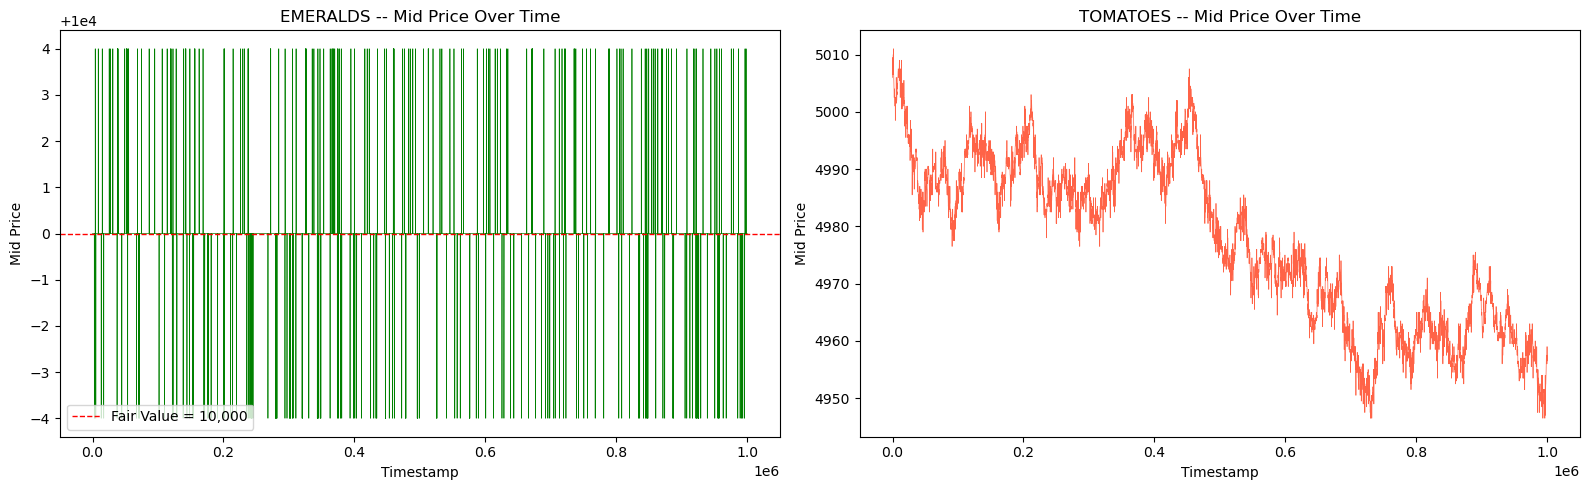

EMERALDS mid_price -- mean: 10000.00, std: 0.72, min: 9996.0, max: 10004.0
TOMATOES mid_price -- mean: 4977.57, std: 14.58, min: 4946.5, max: 5011.0


In [8]:
emeralds = prices_df[prices_df["product"] == "EMERALDS"].copy()
tomatoes = prices_df[prices_df["product"] == "TOMATOES"].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(emeralds["timestamp"], emeralds["mid_price"], linewidth=0.5, color="green")
axes[0].set_title("EMERALDS -- Mid Price Over Time")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Mid Price")
axes[0].axhline(y=10000, color="red", linestyle="--", linewidth=1, label="Fair Value = 10,000")
axes[0].legend()

axes[1].plot(tomatoes["timestamp"], tomatoes["mid_price"], linewidth=0.5, color="tomato")
axes[1].set_title("TOMATOES -- Mid Price Over Time")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Mid Price")

plt.tight_layout()
plt.show()

print(f"EMERALDS mid_price -- mean: {emeralds['mid_price'].mean():.2f}, "
      f"std: {emeralds['mid_price'].std():.2f}, "
      f"min: {emeralds['mid_price'].min()}, max: {emeralds['mid_price'].max()}")
print(f"TOMATOES mid_price -- mean: {tomatoes['mid_price'].mean():.2f}, "
      f"std: {tomatoes['mid_price'].std():.2f}, "
      f"min: {tomatoes['mid_price'].min()}, max: {tomatoes['mid_price'].max()}")

### Observations

- **EMERALDS** is rock-solid at exactly 10,000. The mid_price barely moves. This is a "peg" -- its fair value is known and constant. Strategy: buy anything offered below 10,000, sell anything bid above 10,000.
- **TOMATOES** trends downward over the day (from ~5006 to ~4957). We cannot use a fixed fair value; we need a **moving average** or similar dynamic estimate.

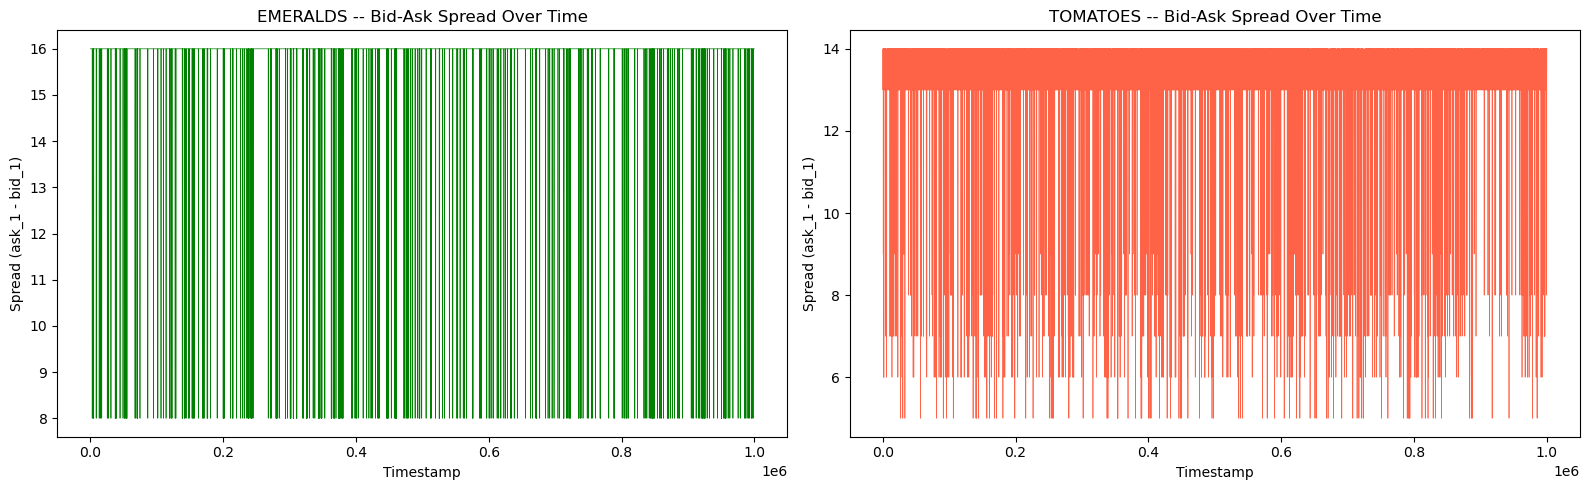

EMERALDS spread -- mean: 15.74, min: 8, max: 16
TOMATOES spread -- mean: 12.98, min: 5, max: 14


In [9]:
emeralds["spread"] = emeralds["ask_price_1"] - emeralds["bid_price_1"]
tomatoes["spread"] = tomatoes["ask_price_1"] - tomatoes["bid_price_1"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(emeralds["timestamp"], emeralds["spread"], linewidth=0.5, color="green")
axes[0].set_title("EMERALDS -- Bid-Ask Spread Over Time")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Spread (ask_1 - bid_1)")

axes[1].plot(tomatoes["timestamp"], tomatoes["spread"], linewidth=0.5, color="tomato")
axes[1].set_title("TOMATOES -- Bid-Ask Spread Over Time")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Spread (ask_1 - bid_1)")

plt.tight_layout()
plt.show()

print(f"EMERALDS spread -- mean: {emeralds['spread'].mean():.2f}, "
      f"min: {emeralds['spread'].min()}, max: {emeralds['spread'].max()}")
print(f"TOMATOES spread -- mean: {tomatoes['spread'].mean():.2f}, "
      f"min: {tomatoes['spread'].min()}, max: {tomatoes['spread'].max()}")

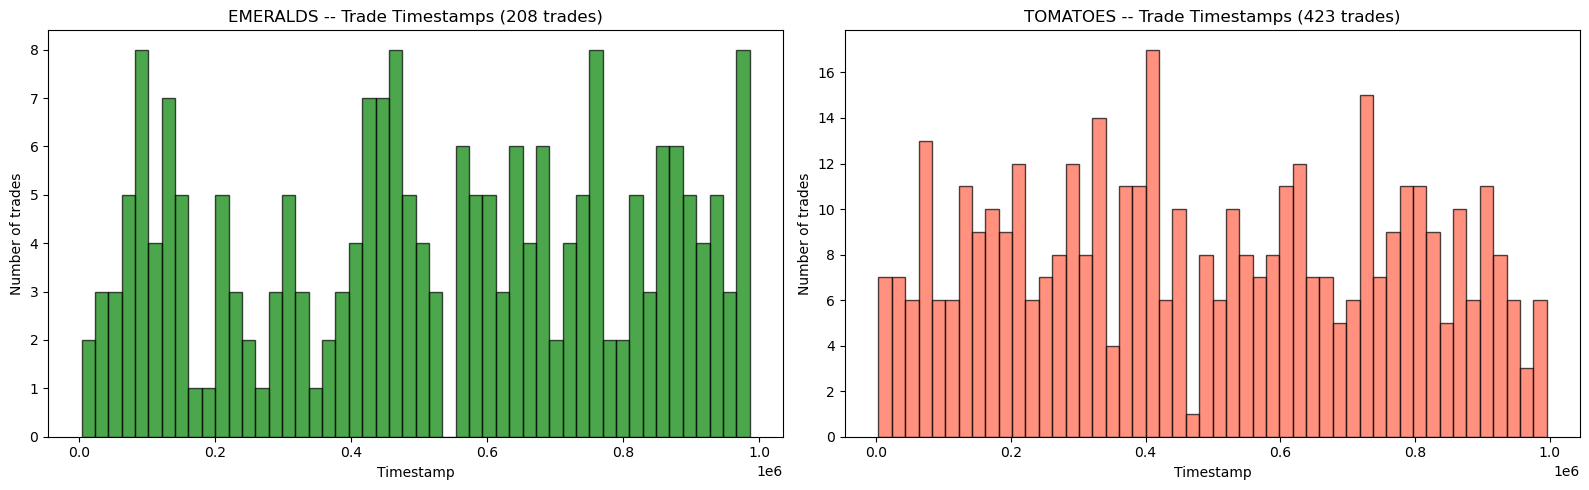

Total trades in the day: 631
  EMERALDS: 208 trades
  TOMATOES: 423 trades

Trading is sparse -- bots only trade a few hundred times in 10,000 iterations.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

em_trades = trades_df[trades_df["symbol"] == "EMERALDS"]
to_trades = trades_df[trades_df["symbol"] == "TOMATOES"]

axes[0].hist(em_trades["timestamp"], bins=50, color="green", alpha=0.7, edgecolor="black")
axes[0].set_title(f"EMERALDS -- Trade Timestamps ({len(em_trades)} trades)")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Number of trades")

axes[1].hist(to_trades["timestamp"], bins=50, color="tomato", alpha=0.7, edgecolor="black")
axes[1].set_title(f"TOMATOES -- Trade Timestamps ({len(to_trades)} trades)")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Number of trades")

plt.tight_layout()
plt.show()

print(f"Total trades in the day: {len(trades_df)}")
print(f"  EMERALDS: {len(em_trades)} trades")
print(f"  TOMATOES: {len(to_trades)} trades")
print(f"\nTrading is sparse -- bots only trade a few hundred times in 10,000 iterations.")

---

# Section C: Understanding the Datamodel (Code Walkthrough)

When you submit a `Trader` class, the platform calls `trader.run(state)` once per iteration. The `state` argument is a `TradingState` object. Let's walk through **every class** in the datamodel so there are no surprises.

All classes live in `datamodel.py` (provided by the challenge, also included in this repo).

---

### Class 1: `Listing`

A `Listing` describes a tradeable product on the exchange.

```python
class Listing:
    def __init__(self, symbol, product, denomination):
        self.symbol = symbol          # e.g. "EMERALDS"
        self.product = product        # e.g. "EMERALDS" (usually same as symbol)
        self.denomination = denomination  # e.g. "XIRECS" (the currency)
```

You rarely need to use Listings directly -- they just confirm which products exist.

---

### Class 2: `OrderDepth`

The most important class for decision-making. It holds the current **order book** for one product.

```python
class OrderDepth:
    buy_orders: Dict[int, int]   # {price: volume, ...}  -- bids (positive volumes)
    sell_orders: Dict[int, int]  # {price: volume, ...}  -- asks (NEGATIVE volumes)
```

**Critical detail**: `sell_orders` volumes are **negative** integers. If you see `{10008: -14}`, it means 14 units are available for sale at price 10,008. The negative sign is the convention for sell-side volume.

`buy_orders` volumes are **positive**. `{9992: 14}` means someone is willing to buy 14 units at 9,992.

---

### Class 3: `Order`

This is what your algorithm sends back. Each `Order` has:

```python
class Order:
    def __init__(self, symbol, price, quantity):
        self.symbol = symbol      # product name, e.g. "EMERALDS"
        self.price = price        # int -- your limit price
        self.quantity = quantity   # int -- POSITIVE = BUY, NEGATIVE = SELL
```

**quantity > 0** = buy order (you want to acquire units)
**quantity < 0** = sell order (you want to offload units)

---

### Class 4: `Trade`

Represents a completed trade (either yours or between bots).

```python
class Trade:
    symbol: str       # product name
    price: int        # execution price
    quantity: int     # number of units traded (always positive)
    buyer: str        # "SUBMISSION" if your algo bought, else "" or bot name
    seller: str       # "SUBMISSION" if your algo sold, else "" or bot name
    timestamp: int    # when it happened
```

You find your own trades in `state.own_trades[product]` and bot-to-bot trades in `state.market_trades[product]`.

---

### Class 5: `Observation` and `ConversionObservation`

Used for conversion mechanics in later rounds. For Tutorial Round 1, you can safely ignore these. Just pass `conversions=0` in your return.

---

### Class 6: `TradingState`

The master object passed to your `run()` method every iteration:

```python
class TradingState:
    traderData: str                              # your serialized state from last iteration
    timestamp: int                               # current time (0, 100, 200, ...)
    listings: Dict[str, Listing]                 # available products
    order_depths: Dict[str, OrderDepth]          # THE ORDER BOOK -- this is the key input
    own_trades: Dict[str, List[Trade]]           # your fills since last iteration
    market_trades: Dict[str, List[Trade]]        # bot-to-bot fills since last iteration
    position: Dict[str, int]                     # your current position per product
    observations: Observation                    # used for conversions (ignore for now)
```

---

### What your `run()` method must return

```python
return result, conversions, traderData
```

| Return value | Type | Meaning |
|-------------|------|---------|
| `result` | `Dict[str, List[Order]]` | Orders to send, keyed by product. |
| `conversions` | `int` | Conversion request count (use 0 for now). |
| `traderData` | `str` | Serialized state to persist to next iteration (use JSON). |

### Hands-On: Building a Mock TradingState from CSV Data

Let's take one row from the prices CSV and manually construct the `TradingState` object that your `run()` method would receive. This makes the mapping from CSV -> code completely concrete.

In [11]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath("datamodel.py")))
from datamodel import Listing, OrderDepth, Trade, TradingState, Order, Observation

# Pick timestamp=0 -- both products exist at this tick
ts0 = prices_df[prices_df["timestamp"] == 0]
print("CSV rows at timestamp 0:")
print(ts0.to_string(index=False))

# --- Build the OrderDepth for EMERALDS from the CSV row ---
em_row = ts0[ts0["product"] == "EMERALDS"].iloc[0]

em_depth = OrderDepth()
em_depth.buy_orders = {
    int(em_row["bid_price_1"]): int(em_row["bid_volume_1"]),
    int(em_row["bid_price_2"]): int(em_row["bid_volume_2"]),
}
em_depth.sell_orders = {
    int(em_row["ask_price_1"]): -int(em_row["ask_volume_1"]),
    int(em_row["ask_price_2"]): -int(em_row["ask_volume_2"]),
}

print(f"\nEMERALDS OrderDepth at t=0:")
print(f"  buy_orders  (bids): {em_depth.buy_orders}")
print(f"  sell_orders (asks): {em_depth.sell_orders}")

# --- Build the OrderDepth for TOMATOES from the CSV row ---
to_row = ts0[ts0["product"] == "TOMATOES"].iloc[0]

to_depth = OrderDepth()
to_depth.buy_orders = {
    int(to_row["bid_price_1"]): int(to_row["bid_volume_1"]),
    int(to_row["bid_price_2"]): int(to_row["bid_volume_2"]),
}
to_depth.sell_orders = {
    int(to_row["ask_price_1"]): -int(to_row["ask_volume_1"]),
    int(to_row["ask_price_2"]): -int(to_row["ask_volume_2"]),
}

print(f"\nTOMATOES OrderDepth at t=0:")
print(f"  buy_orders  (bids): {to_depth.buy_orders}")
print(f"  sell_orders (asks): {to_depth.sell_orders}")

CSV rows at timestamp 0:
 day  timestamp  product  bid_price_1  bid_volume_1  bid_price_2  bid_volume_2  bid_price_3  bid_volume_3  ask_price_1  ask_volume_1  ask_price_2  ask_volume_2  ask_price_3  ask_volume_3  mid_price  profit_and_loss
  -1          0 TOMATOES         4999             5         4998            15          NaN           NaN         5013             5         5014            15          NaN           NaN     5006.0              0.0
  -1          0 EMERALDS         9992            14         9990            29          NaN           NaN        10008            14        10010            29          NaN           NaN    10000.0              0.0

EMERALDS OrderDepth at t=0:
  buy_orders  (bids): {9992: 14, 9990: 29}
  sell_orders (asks): {10008: -14, 10010: -29}

TOMATOES OrderDepth at t=0:
  buy_orders  (bids): {4999: 5, 4998: 15}
  sell_orders (asks): {5013: -5, 5014: -15}


In [12]:
# --- Assemble the full TradingState ---
listings = {
    "EMERALDS": Listing(symbol="EMERALDS", product="EMERALDS", denomination="XIRECS"),
    "TOMATOES": Listing(symbol="TOMATOES", product="TOMATOES", denomination="XIRECS"),
}

state = TradingState(
    traderData="",                                    # empty on first call
    timestamp=0,                                      # first iteration
    listings=listings,
    order_depths={"EMERALDS": em_depth, "TOMATOES": to_depth},
    own_trades={"EMERALDS": [], "TOMATOES": []},      # no trades yet
    market_trades={"EMERALDS": [], "TOMATOES": []},   # no bot trades at t=0
    position={"EMERALDS": 0, "TOMATOES": 0},          # flat position at start
    observations=Observation({}, {}),
)

print("=== Mock TradingState at t=0 ===")
print(f"timestamp     : {state.timestamp}")
print(f"traderData    : '{state.traderData}'")
print(f"position      : {state.position}")
print(f"products      : {list(state.order_depths.keys())}")
print()
for prod in state.order_depths:
    od = state.order_depths[prod]
    print(f"  {prod}:")
    print(f"    buy_orders  = {od.buy_orders}")
    print(f"    sell_orders = {od.sell_orders}")
    best_bid = max(od.buy_orders.keys())
    best_ask = min(od.sell_orders.keys())
    print(f"    best_bid={best_bid}, best_ask={best_ask}, mid={(best_bid+best_ask)/2}")
    print()

=== Mock TradingState at t=0 ===
timestamp     : 0
traderData    : ''
position      : {'EMERALDS': 0, 'TOMATOES': 0}
products      : ['EMERALDS', 'TOMATOES']

  EMERALDS:
    buy_orders  = {9992: 14, 9990: 29}
    sell_orders = {10008: -14, 10010: -29}
    best_bid=9992, best_ask=10008, mid=10000.0

  TOMATOES:
    buy_orders  = {4999: 5, 4998: 15}
    sell_orders = {5013: -5, 5014: -15}
    best_bid=4999, best_ask=5013, mid=5006.0



### How to Read the Order Book (Visual Example)

For EMERALDS at t=0, the order book looks like this:

```
                SELL SIDE (asks -- available to buy from)
                ┌─────────────────────────────────────┐
Price 10010  :  │  29 units for sale  (ask_price_2)   │
Price 10008  :  │  14 units for sale  (ask_price_1)   │  ← Best Ask
                └─────────────────────────────────────┘
                         --- SPREAD = 16 ---
                ┌─────────────────────────────────────┐
Price  9992  :  │  14 units to buy    (bid_price_1)   │  ← Best Bid
Price  9990  :  │  29 units to buy    (bid_price_2)   │
                └─────────────────────────────────────┘
                BUY SIDE (bids -- willing to buy from you)

Mid Price = (9992 + 10008) / 2 = 10000
```

If you send `Order("EMERALDS", 10008, 5)` (buy 5 at 10008), you immediately trade with the ask at 10008 and get 5 units at price 10008.

If you send `Order("EMERALDS", 9992, -5)` (sell 5 at 9992), you immediately trade with the bid at 9992 and offload 5 units.

---

# Section D: Understanding the Execution Model

This section covers how the simulation actually runs your code, how orders get matched, and the constraints you must respect.

---

## D.1: The Simulation Loop

The simulation runs for **10,000 iterations** (timestamps 0, 100, 200, ..., 999900). At each iteration:

```
┌────────────────────────────────────────────────────────────────────────┐
│                        ONE ITERATION (e.g. t=500)                     │
│                                                                       │
│  1. Platform builds TradingState:                                     │
│     - Snapshots current order book (bot quotes)                       │
│     - Includes your trades from last iteration (own_trades)           │
│     - Includes bot-to-bot trades from last iteration (market_trades)  │
│     - Includes your current position                                  │
│     - Includes your traderData from last iteration                    │
│                                                                       │
│  2. Platform calls: result, conversions, traderData = trader.run(state)│
│     (Your code runs here -- you have 900ms max)                       │
│                                                                       │
│  3. Platform validates your orders:                                   │
│     - Checks position limits (see below)                              │
│     - If invalid → ALL orders for that product are cancelled          │
│                                                                       │
│  4. Platform matches your orders against bot quotes:                  │
│     - Buy order at price >= best ask → immediate trade                │
│     - Sell order at price <= best bid → immediate trade               │
│     - Partially filled? Remainder posted as your quote                │
│                                                                       │
│  5. Bots react to your remaining quotes:                              │
│     - Bots may trade against your leftover orders                     │
│     - If no bot trades → your leftover orders are CANCELLED           │
│                                                                       │
│  6. Bots trade with each other (generates market_trades for next iter)│
│                                                                       │
│  7. Platform saves your traderData string for next iteration          │
│                                                                       │
│  → Proceed to iteration t=600                                         │
└────────────────────────────────────────────────────────────────────────┘
```

**Key takeaway**: Your orders are instantaneous -- you always get priority over bots. Any leftover quantity that bots don't pick up is auto-cancelled.

---

## D.2: Order Matching -- How Trades Happen

When you send orders, the exchange matching engine works like this:

**Buy order** at price P with quantity Q:
- Looks at all `sell_orders` in the order book
- If any ask_price <= P, your order trades at the ask_price (you get the better price)
- Fills from cheapest ask upward until your quantity is exhausted
- Leftover quantity (if any) is posted as a bid at price P for bots to see

**Sell order** at price P with quantity Q (Q is negative):
- Looks at all `buy_orders` in the order book
- If any bid_price >= P, your order trades at the bid_price
- Fills from highest bid downward until your quantity is exhausted
- Leftover quantity posted as an ask at price P for bots to see

**Example**: Order book has `sell_orders = {10008: -14, 10010: -29}`. You send `Order("EMERALDS", 10010, 20)`:
1. First fills 14 units at 10008 (cheaper ask goes first)
2. Then fills 6 units at 10010
3. Total: 20 units bought. No leftover.

---

## D.3: Position Limits

Every product has a **position limit** -- the maximum absolute position you can hold.

- If the limit is 20, your position must stay in the range [-20, +20].
- The exchange checks: "If ALL buy orders were fully filled, would position exceed +limit? If ALL sell orders were fully filled, would position exceed -limit?"
- If **yes** for either side, **ALL orders for that product in that iteration are cancelled** (not just the excess).
- This means you must be careful to calculate how much you can buy/sell given your current position.

**Position-aware order sizing formula**:

```
max_buy_quantity  = position_limit - current_position
max_sell_quantity = position_limit + current_position   (send as negative)
```

For example, if limit=20 and position=+7:
- You can buy at most 20 - 7 = 13 more units
- You can sell at most 20 + 7 = 27 units (but you only hold 7, so selling > 7 means going short)

---

## D.4: State Persistence via `traderData`

The platform runs on AWS Lambda -- **no state persists between iterations** by default. Class variables, global variables -- all reset.

The solution: the `traderData` string. Whatever string you return as the third element of your `run()` output gets passed back to you as `state.traderData` on the next call.

**How to use it**: Serialize any data you need to JSON.

```python
import json

# Saving state (at the end of run()):
my_state = {"price_history": [10000, 10001, 9999], "trade_count": 5}
traderData = json.dumps(my_state)

# Restoring state (at the start of run()):
if state.traderData:
    my_state = json.loads(state.traderData)
else:
    my_state = {"price_history": [], "trade_count": 0}
```

**Limit**: The string is capped at 50,000 characters. Don't store unbounded histories -- use a rolling window.

---

## D.5: The `bid()` Method

Your `Trader` class must also define a `bid()` method. This is only used in Algorithmic Round 2 and is ignored in all other rounds. Just return a fixed integer:

```python
def bid(self):
    return 15
```

You can safely include this in every submission.

---

# Section E: Building the Trader -- Three Strategies

We will build three progressively more sophisticated strategies:

1. **Strategy 1: "Do Nothing"** -- A minimal valid submission that sends zero orders. Useful to verify the skeleton compiles on the platform.
2. **Strategy 2: Fixed Fair Value Taker (EMERALDS)** -- Exploit the fact that EMERALDS is pegged at 10,000.
3. **Strategy 3: SMA-Based Taker (TOMATOES)** -- Use a simple moving average to dynamically estimate fair value for a trending product.

Finally, we combine Strategies 2 and 3 into a single `Trader` class for submission.

---

## Strategy 1: "Do Nothing" Baseline

The absolute minimum valid submission. It receives the state, does nothing, and returns empty order lists.

In [13]:
from datamodel import OrderDepth, TradingState, Order
from typing import List, Dict

class TraderV1:
    """Strategy 1: Do Nothing. Valid submission that sends no orders."""

    def bid(self):
        return 15

    def run(self, state: TradingState):
        result: Dict[str, List[Order]] = {}
        for product in state.order_depths:
            result[product] = []

        traderData = ""
        conversions = 0
        return result, conversions, traderData

# Quick test with our mock state
trader_v1 = TraderV1()
res, conv, td = trader_v1.run(state)
print("Strategy 1 output:")
print(f"  Orders: { {k: [str(o) for o in v] for k, v in res.items()} }")
print(f"  Conversions: {conv}")
print(f"  traderData: '{td}'")

Strategy 1 output:
  Orders: {'EMERALDS': [], 'TOMATOES': []}
  Conversions: 0
  traderData: ''


---

## Strategy 2: Fixed Fair Value Market Taker (EMERALDS)

From Section B we know EMERALDS has a stable mid_price of exactly 10,000. The bots place bids around 9,992 and asks around 10,008.

**Strategy**: If anyone is selling below 10,000, we buy. If anyone is buying above 10,000, we sell. We sweep all profitable levels in the order book, not just the best one.

**Position limit**: We assume 20 for both products (typical for tutorial rounds). We carefully track how much room we have to buy or sell.

### Detailed Logic Walkthrough

```
For each ask_price in sell_orders (sorted low to high):
    if ask_price < fair_value AND we have room to buy:
        buy as many units as we can (capped by position limit)

For each bid_price in buy_orders (sorted high to low):
    if bid_price > fair_value AND we have room to sell:
        sell as many units as we can (capped by position limit)
```

In [14]:
class TraderV2:
    """Strategy 2: Fixed fair value taker for EMERALDS only."""

    FAIR_VALUE = {"EMERALDS": 10_000}
    POSITION_LIMITS = {"EMERALDS": 20, "TOMATOES": 20}

    def bid(self):
        return 15

    def run(self, state: TradingState):
        result: Dict[str, List[Order]] = {}

        for product in state.order_depths:
            order_depth: OrderDepth = state.order_depths[product]
            orders: List[Order] = []
            position = state.position.get(product, 0)
            limit = self.POSITION_LIMITS.get(product, 20)

            if product not in self.FAIR_VALUE:
                result[product] = []
                continue

            fair = self.FAIR_VALUE[product]

            # --- BUY: sweep asks below fair value ---
            for ask_price in sorted(order_depth.sell_orders.keys()):
                if ask_price >= fair:
                    break
                ask_vol = order_depth.sell_orders[ask_price]  # negative
                can_buy = limit - position
                if can_buy <= 0:
                    break
                buy_qty = min(-ask_vol, can_buy)  # -ask_vol makes it positive
                orders.append(Order(product, ask_price, buy_qty))
                position += buy_qty

            # --- SELL: sweep bids above fair value ---
            for bid_price in sorted(order_depth.buy_orders.keys(), reverse=True):
                if bid_price <= fair:
                    break
                bid_vol = order_depth.buy_orders[bid_price]  # positive
                can_sell = limit + position
                if can_sell <= 0:
                    break
                sell_qty = min(bid_vol, can_sell)
                orders.append(Order(product, bid_price, -sell_qty))
                position -= sell_qty

            result[product] = orders

        return result, 0, ""

# Test with mock state
trader_v2 = TraderV2()
res, _, _ = trader_v2.run(state)
print("Strategy 2 output:")
for prod, ords in res.items():
    if ords:
        print(f"  {prod}: {[str(o) for o in ords]}")
    else:
        print(f"  {prod}: (no orders -- no fair value defined or nothing profitable)")

print("\nExplanation:")
print("  EMERALDS: best ask = 10008, best bid = 9992. Fair = 10000.")
print("  Neither ask < 10000 nor bid > 10000, so no trades. This is expected!")
print("  Profit comes from occasional mispricings when the order book shifts.")

Strategy 2 output:
  EMERALDS: (no orders -- no fair value defined or nothing profitable)
  TOMATOES: (no orders -- no fair value defined or nothing profitable)

Explanation:
  EMERALDS: best ask = 10008, best bid = 9992. Fair = 10000.
  Neither ask < 10000 nor bid > 10000, so no trades. This is expected!
  Profit comes from occasional mispricings when the order book shifts.


---

## Strategy 3: Simple Moving Average Taker (TOMATOES)

TOMATOES trends over time, so we cannot use a fixed fair value. Instead, we estimate fair value as the **simple moving average (SMA)** of the last N mid-prices.

### How it works:

1. Each iteration, compute the current mid-price from the order book.
2. Append it to a rolling history (persisted via `traderData` as JSON).
3. Fair value = mean of the last N mid-prices (we use N=20).
4. Buy anything offered below fair value; sell anything bid above it.
5. Respect position limits.

### Why SMA works here:

- SMA smooths out noise and adapts to trends.
- With N=20, the fair value lags behind the true price by about 10 ticks, which is fine for a starting strategy.
- If the price drops, the SMA eventually follows, preventing us from buying into a falling knife for too long.

In [16]:
import json

class TraderV3:
    """Strategy 3: SMA-based taker for TOMATOES, fixed value for EMERALDS."""

    POSITION_LIMITS = {"EMERALDS": 20, "TOMATOES": 20}
    EMERALDS_FAIR = 10_000
    SMA_WINDOW = 20  # number of past mid-prices to average

    def bid(self):
        return 15

    def run(self, state: TradingState):
        result: Dict[str, List[Order]] = {}

        # --- Restore state ---
        if state.traderData:
            saved = json.loads(state.traderData)
        else:
            saved = {"tomatoes_history": []}

        tomatoes_history: list = saved.get("tomatoes_history", [])

        for product in state.order_depths:
            order_depth: OrderDepth = state.order_depths[product]
            orders: List[Order] = []
            position = state.position.get(product, 0)
            limit = self.POSITION_LIMITS.get(product, 20)

            # --- Determine fair value ---
            if product == "EMERALDS":
                fair = self.EMERALDS_FAIR
            elif product == "TOMATOES":
                best_bid = max(order_depth.buy_orders.keys()) if order_depth.buy_orders else 0
                best_ask = min(order_depth.sell_orders.keys()) if order_depth.sell_orders else 0
                if best_bid and best_ask:
                    current_mid = (best_bid + best_ask) / 2
                else:
                    current_mid = best_bid or best_ask
                tomatoes_history.append(current_mid)

                # Keep only last SMA_WINDOW values to avoid traderData bloat
                if len(tomatoes_history) > self.SMA_WINDOW:
                    tomatoes_history = tomatoes_history[-self.SMA_WINDOW:]

                fair = sum(tomatoes_history) / len(tomatoes_history)
            else:
                result[product] = []
                continue

            # --- BUY: sweep asks below fair value ---
            for ask_price in sorted(order_depth.sell_orders.keys()):
                if ask_price >= fair:
                    break
                ask_vol = order_depth.sell_orders[ask_price]
                can_buy = limit - position
                if can_buy <= 0:
                    break
                buy_qty = min(-ask_vol, can_buy)
                orders.append(Order(product, ask_price, buy_qty))
                position += buy_qty

            # --- SELL: sweep bids above fair value ---
            for bid_price in sorted(order_depth.buy_orders.keys(), reverse=True):
                if bid_price <= fair:
                    break
                bid_vol = order_depth.buy_orders[bid_price]
                can_sell = limit + position
                if can_sell <= 0:
                    break
                sell_qty = min(bid_vol, can_sell)
                orders.append(Order(product, bid_price, -sell_qty))
                position -= sell_qty

            result[product] = orders

        # --- Save state ---
        saved["tomatoes_history"] = tomatoes_history
        traderData = json.dumps(saved)

        return result, 0, traderData

# Test with mock state
trader_v3 = TraderV3()
res, conv, td = trader_v3.run(state)
print("Strategy 3 output at t=0:")
for prod, ords in res.items():
    print(f"  {prod}: {[str(o) for o in ords] if ords else '(no profitable orders)'}")
print(f"\n  traderData saved: {td}")
print(f"\n  (At t=0 with only 1 data point, SMA = current mid-price."
      f"\n   As more data accumulates, the SMA smooths the estimate.)")

Strategy 3 output at t=0:
  EMERALDS: (no profitable orders)
  TOMATOES: (no profitable orders)

  traderData saved: {"tomatoes_history": [5006.0]}

  (At t=0 with only 1 data point, SMA = current mid-price.
   As more data accumulates, the SMA smooths the estimate.)


### Strategy Comparison Summary

| Aspect | Strategy 1 (Do Nothing) | Strategy 2 (Fixed Value) | Strategy 3 (SMA) |
|--------|------------------------|--------------------------|-------------------|
| Products | All (ignored) | EMERALDS only | EMERALDS + TOMATOES |
| Fair Value | N/A | Fixed at 10,000 | Fixed for EMERALDS; SMA for TOMATOES |
| State | None | None | Stores price history in traderData |
| Position-Aware | N/A | Yes | Yes |
| Expected PnL | 0 | Positive (EMERALDS) | Positive (both) |

The final `trader.py` submission uses Strategy 3 logic, which handles both products.

In [36]:
from datamodel import OrderDepth, TradingState, Order
import json
import numpy as np
import math
from statistics import NormalDist

POS_LIMITS = {
    STATIC_SYMBOL: 20, 
}

# This is the base ProductTrader class that has all the commonly used utility attributes and methods already implemented for individual traders
class ProductTrader:

    def __init__(self, name, state, prints, new_trader_data, product_group=None):

        self.orders = []

        self.name = name
        self.state = state
        self.prints = prints
        self.new_trader_data = new_trader_data
        self.product_group = name if product_group is None else product_group

        self.last_traderData = self.get_last_traderData()

        self.position_limit = POS_LIMITS.get(self.name, 0)
        self.initial_position = self.state.position.get(self.name, 0) # position at beginning of round

        self.expected_position = self.initial_position # update this if you expect a certain change in position e.g. to already hedge


        self.mkt_buy_orders, self.mkt_sell_orders = self.get_order_depth()
        self.bid_wall, self.wall_mid, self.ask_wall = self.get_walls()
        self.best_bid, self.best_ask = self.get_best_bid_ask()

        self.max_allowed_buy_volume, self.max_allowed_sell_volume = self.get_max_allowed_volume() # gets updated when order created
        self.total_mkt_buy_volume, self.total_mkt_sell_volume = self.get_total_market_buy_sell_volume()

    def get_last_traderData(self):
                        
        last_traderData = {}
        try:
            if self.state.traderData != '':
                last_traderData = json.loads(self.state.traderData)
        except: self.log("ERROR", 'td')

        return last_traderData


    def get_best_bid_ask(self):

        best_bid = best_ask = None

        try:
            if len(self.mkt_buy_orders) > 0:
                best_bid = max(self.mkt_buy_orders.keys())
            if len(self.mkt_sell_orders) > 0:
                best_ask = min(self.mkt_sell_orders.keys())
        except: pass

        return best_bid, best_ask


    def get_walls(self):

        bid_wall = wall_mid = ask_wall = None

        try: bid_wall = min([x for x,_ in self.mkt_buy_orders.items()])
        except: pass
        
        try: ask_wall = max([x for x,_ in self.mkt_sell_orders.items()])
        except: pass

        try: wall_mid = (bid_wall + ask_wall) / 2
        except: pass

        return bid_wall, wall_mid, ask_wall
    
    def get_total_market_buy_sell_volume(self):

        market_bid_volume = market_ask_volume = 0

        try:
            market_bid_volume = sum([v for p, v in self.mkt_buy_orders.items()])
            market_ask_volume = sum([v for p, v in self.mkt_sell_orders.items()])
        except: pass

        return market_bid_volume, market_ask_volume
    

    def get_max_allowed_volume(self):
        max_allowed_buy_volume = self.position_limit - self.initial_position
        max_allowed_sell_volume = self.position_limit + self.initial_position
        return max_allowed_buy_volume, max_allowed_sell_volume

    def get_order_depth(self):

        order_depth, buy_orders, sell_orders = {}, {}, {}

        try: order_depth: OrderDepth = self.state.order_depths[self.name]
        except: pass
        try: buy_orders = {bp: abs(bv) for bp, bv in sorted(order_depth.buy_orders.items(), key=lambda x: x[0], reverse=True)}
        except: pass
        try: sell_orders = {sp: abs(sv) for sp, sv in sorted(order_depth.sell_orders.items(), key=lambda x: x[0])}
        except: pass

        return buy_orders, sell_orders
    

    def bid(self, price, volume, logging=True):
        abs_volume = min(abs(int(volume)), self.max_allowed_buy_volume)
        order = Order(self.name, int(price), abs_volume)
        # if logging: self.log("BUYO", {"p":price, "s":self.name, "v":int(volume)}, product_group='ORDERS')
        self.max_allowed_buy_volume -= abs_volume
        self.orders.append(order)

    def ask(self, price, volume, logging=True):
        abs_volume = min(abs(int(volume)), self.max_allowed_sell_volume)
        order = Order(self.name, int(price), -abs_volume)
        # if logging: self.log("SELLO", {"p":price, "s":self.name, "v":int(volume)}, product_group='ORDERS')
        self.max_allowed_sell_volume -= abs_volume
        self.orders.append(order)

    def log(self, kind, message, product_group=None):
        if product_group is None: product_group = self.product_group

        if product_group == 'ORDERS':
            group = self.prints.get(product_group, [])
            group.append({kind: message})
        else:
            group = self.prints.get(product_group, {})
            group[kind] = message

        self.prints[product_group] = group

    def check_for_informed(self):

        informed_direction, informed_bought_ts, informed_sold_ts = NEUTRAL, None, None
        

        informed_bought_ts, informed_sold_ts = self.last_traderData.get(self.name, [None, None])

        trades = self.state.market_trades.get(self.name, []) + self.state.own_trades.get(self.name, [])

        for trade in trades:
            if trade.buyer == INFORMED_TRADER_ID:
                informed_bought_ts = trade.timestamp
            if trade.seller == INFORMED_TRADER_ID: 
                informed_sold_ts = trade.timestamp
            
        self.new_trader_data[self.name] = [informed_bought_ts, informed_sold_ts]

        informed_sold = informed_sold_ts is not None
        informed_bought = informed_bought_ts is not None

        if not informed_bought and not informed_sold:
            informed_direction = NEUTRAL

        elif not informed_bought and informed_sold:
            informed_direction = SHORT

        elif informed_bought and not informed_sold:
            informed_direction = LONG

        elif informed_bought and informed_sold:
            if informed_sold_ts > informed_bought_ts:
                informed_direction = SHORT
            elif informed_sold_ts < informed_bought_ts:
                informed_direction = LONG
            else:
                informed_direction = NEUTRAL

        self.log('TD', self.new_trader_data[self.name])
        self.log('ID', informed_direction)

        return informed_direction, informed_bought_ts, informed_sold_ts


    def get_orders(self):
        # overwrite this in each trader
        return {}


class StaticTrader(ProductTrader):
    def __init__(self, state, prints, new_trader_data):
        super().__init__(STATIC_SYMBOL, state, prints, new_trader_data)

    def get_orders(self):
        print(self.wall_mid)
        if self.wall_mid is not None:

            ##########################################################
            ####### 1. TAKING
            ##########################################################
            for sp, sv in self.mkt_sell_orders.items(): ## Getting the number of open sell orders in the market
                if sp <= self.wall_mid - 1:  ### Checking if the given sell price is present between the mid wall of the following
                    self.bid(sp, sv, logging=False)
                elif sp <= self.wall_mid and self.initial_position < 0:  ## If the price is not favourable then will buy the quantity to exit from the short position
                        volume = min(sv,  abs(self.initial_position))
                        self.bid(sp, volume, logging=False)

            for bp, bv in self.mkt_buy_orders.items():
                if bp >= self.wall_mid + 1:
                    self.ask(bp, bv, logging=False)
                elif bp >= self.wall_mid and self.initial_position > 0:
                        volume = min(bv,  self.initial_position)
                        self.ask(bp, volume, logging=False)

            ###########################################################
            ####### 2. MAKING
            ### Overall the purpose of this is to generate pressure in the market by selling above the maximum 
            ## possible sell and buying below the minimum possible buy and create the market conditions in one's favour
            ###########################################################
            bid_price = int(self.bid_wall + 1) # base case
            ask_price = int(self.ask_wall - 1) # base case

            # OVERBIDDING: overbid best bid that is still under the mid wall
            for bp, bv in self.mkt_buy_orders.items():
                overbidding_price = bp + 1
                if bv > 1 and overbidding_price < self.wall_mid:
                    bid_price = max(bid_price, overbidding_price)
                    break
                elif bp < self.wall_mid:
                    bid_price = max(bid_price, bp)
                    break

            # UNDERBIDDING: underbid best ask that is still over the mid wall
            for sp, sv in self.mkt_sell_orders.items():
                underbidding_price = sp - 1
                if sv > 1 and underbidding_price > self.wall_mid:
                    ask_price = min(ask_price, underbidding_price)
                    break
                elif sp > self.wall_mid:
                    ask_price = min(ask_price, sp)
                    break

            # POST ORDERS
            self.bid(bid_price, self.max_allowed_buy_volume)
            self.ask(ask_price, self.max_allowed_sell_volume)


        return {self.name: self.orders}

STATIC_SYMBOL = "EMERALDS"


class NewTrader:

    def run(self, state: TradingState):
        result:dict[str,list[Order]] = {}
        new_trader_data = {}
        prints = {
            "GENERAL": {
                "TIMESTAMP": state.timestamp,
                "POSITIONS": state.position
            },
        }

        def export(prints):
            try: print(json.dumps(prints))
            except: pass


        product_traders = {
            STATIC_SYMBOL: StaticTrader
        }

        result, conversions = {}, 0
        for symbol, product_trader in product_traders.items():
            print(symbol)
            if symbol in state.order_depths:
                try:
                    trader = product_trader(state, prints, new_trader_data)
                    result.update(trader.get_orders())
                except: pass        
        try:
            final_trader_data = json.dumps(new_trader_data)
        except Exception as e: 
            final_trader_data = ''


        export(prints)
        return result, 0, final_trader_data


---

# Section F: Local Backtesting Harness

Before uploading to the platform, we want to **replay the historical CSV data** through our trader and see how it would have performed. This backtester:

1. Groups the prices CSV by timestamp (one group = one iteration).
2. For each timestamp, builds an `OrderDepth` from the CSV row for each product.
3. Constructs a `TradingState` and calls `trader.run(state)`.
4. Simulates order matching: checks which of the trader's orders would have filled against the order book.
5. Tracks position, cash, and PnL.
6. Plots the equity curve.

**Important caveat**: This is a simplified backtest. On the real platform, bots also react to your quotes (leftover orders). Our backtest only simulates immediate fills against the snapshot -- it ignores the bot-reaction step. Still, it gives a useful lower-bound estimate.

In [37]:
def build_order_depth_from_row(row) -> OrderDepth:
    """Convert one CSV row into an OrderDepth object."""
    od = OrderDepth()
    for level in [1, 2, 3]:
        bp = row.get(f"bid_price_{level}")
        bv = row.get(f"bid_volume_{level}")
        if pd.notna(bp) and pd.notna(bv):
            od.buy_orders[int(bp)] = int(bv)
        ap = row.get(f"ask_price_{level}")
        av = row.get(f"ask_volume_{level}")
        if pd.notna(ap) and pd.notna(av):
            od.sell_orders[int(ap)] = -int(av)  # negative convention
    return od


def simulate_fills(orders: List[Order], order_depth: OrderDepth, position: int, limit: int):
    """
    Simulate immediate order matching against the order book snapshot.
    Returns list of (price, signed_quantity) fills and the new position.
    """
    fills = []

    # Check position limit: would all orders cause a breach?
    total_buy = sum(o.quantity for o in orders if o.quantity > 0)
    total_sell = sum(-o.quantity for o in orders if o.quantity < 0)
    if position + total_buy > limit or position - total_sell < -limit:
        return [], position  # all orders cancelled

    for order in orders:
        if order.quantity > 0:
            # Buy order -- match against asks
            remaining = order.quantity
            for ask_price in sorted(order_depth.sell_orders.keys()):
                if ask_price > order.price or remaining <= 0:
                    break
                available = -order_depth.sell_orders[ask_price]
                fill_qty = min(remaining, available)
                fills.append((ask_price, fill_qty))
                position += fill_qty
                remaining -= fill_qty
        elif order.quantity < 0:
            # Sell order -- match against bids
            remaining = -order.quantity
            for bid_price in sorted(order_depth.buy_orders.keys(), reverse=True):
                if bid_price < order.price or remaining <= 0:
                    break
                available = order_depth.buy_orders[bid_price]
                fill_qty = min(remaining, available)
                fills.append((bid_price, -fill_qty))
                position -= fill_qty
                remaining -= fill_qty

    return fills, position


def backtest(trader, prices_csv_path: str, position_limits: dict):
    """
    Replay a prices CSV through a trader and return a DataFrame of results.
    """
    df = pd.read_csv(prices_csv_path)
    products = df["product"].unique().tolist()
    timestamps = sorted(df["timestamp"].unique())

    listings = {p: Listing(symbol=p, product=p, denomination="XIRECS") for p in products}
    positions = {p: 0 for p in products}
    cash = 0.0
    trader_data = ""

    records = []

    for ts in timestamps:
        ts_rows = df[df["timestamp"] == ts]

        # Build order depths
        order_depths = {}
        mid_prices = {}
        for _, row in ts_rows.iterrows():
            prod = row["product"]
            order_depths[prod] = build_order_depth_from_row(row)
            mid_prices[prod] = row["mid_price"]

        # Build TradingState
        state = TradingState(
            traderData=trader_data,
            timestamp=int(ts),
            listings=listings,
            order_depths=order_depths,
            own_trades={p: [] for p in products},
            market_trades={p: [] for p in products},
            position=dict(positions),
            observations=Observation({}, {}),
        )

        # Run trader
        orders_dict, conversions, trader_data = trader.run(state)

        # Simulate fills for each product
        iteration_pnl = 0.0
        for prod in products:
            prod_orders = orders_dict.get(prod, [])
            limit = position_limits.get(prod, 20)
            fills, new_pos = simulate_fills(
                prod_orders, order_depths[prod], positions[prod], limit
            )
            for price, qty in fills:
                cash -= price * qty  # buy: qty>0, cash decreases; sell: qty<0, cash increases
            positions[prod] = new_pos

        # Mark-to-market PnL: cash + sum(position * mid_price)
        mtm = cash + sum(positions[p] * mid_prices.get(p, 0) for p in products)
        records.append({
            "timestamp": ts,
            "cash": cash,
            "pos_EMERALDS": positions.get("EMERALDS", 0),
            "pos_TOMATOES": positions.get("TOMATOES", 0),
            "mtm_pnl": mtm,
        })

    return pd.DataFrame(records)

print("Backtester defined. Ready to run.")

Backtester defined. Ready to run.


<Axes: >

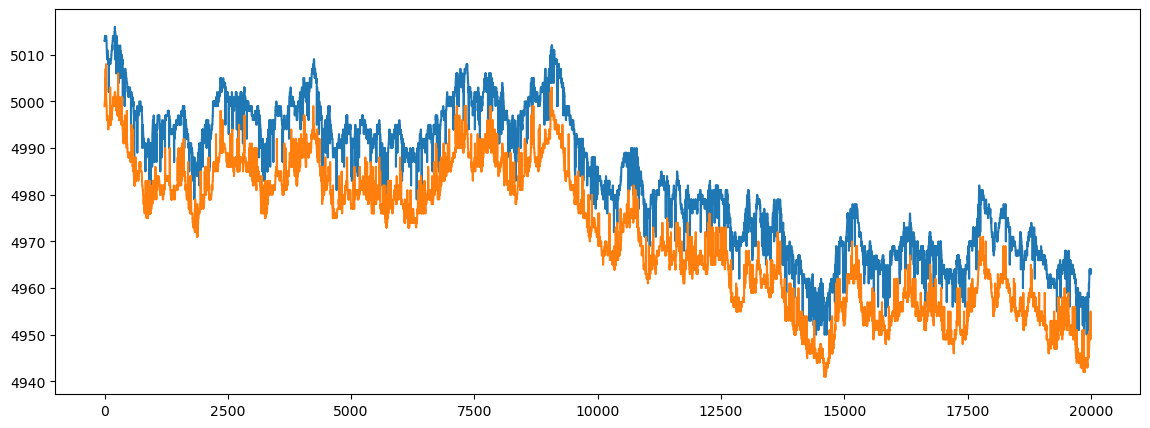

In [57]:
df = pd.read_csv('prices_round_0_day_-1.csv')
tom_df = df[df['product']=='TOMATOES']
tom_df['ask_price_1'].plot()
tom_df['bid_price_1'].plot()

### Run the Backtest: Strategy 1 (Do Nothing) vs Strategy 3 (SMA Taker)

In [38]:
limits = {"EMERALDS": 20, "TOMATOES": 20}

print("Running backtest for Strategy 1 (Do Nothing)...")
bt_v1 = backtest(TraderV1(), "prices_round_0_day_-1.csv", limits)

print("Running backtest for Strategy 3 (SMA Taker)...")
bt_v3 = backtest(TraderV3(), "prices_round_0_day_-1.csv", limits)

print("Done.")

Running backtest for Strategy 1 (Do Nothing)...
Running backtest for Strategy 3 (SMA Taker)...
Done.


In [54]:
df = pd.read_csv('prices_round_0_day_-2.csv')
em_df = df[df['product']=='EMERALDS']

em_df['ask_price_3'].value_counts()


ask_price_3
10010.0    170
Name: count, dtype: int64

In [39]:
print("Running backtest for Strategy 4 (New Trader)...")
bt_new = backtest(NewTrader(), "prices_round_0_day_-1.csv", limits)

Running backtest for Strategy 4 (New Trader)...
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 0, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 100, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 200, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 300, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 400, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 500, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 600, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 700, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 800, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000.0
{"GENERAL": {"TIMESTAMP": 900, "POSITIONS": {"TOMATOES": 0, "EMERALDS": 0}}}
EMERALDS
10000

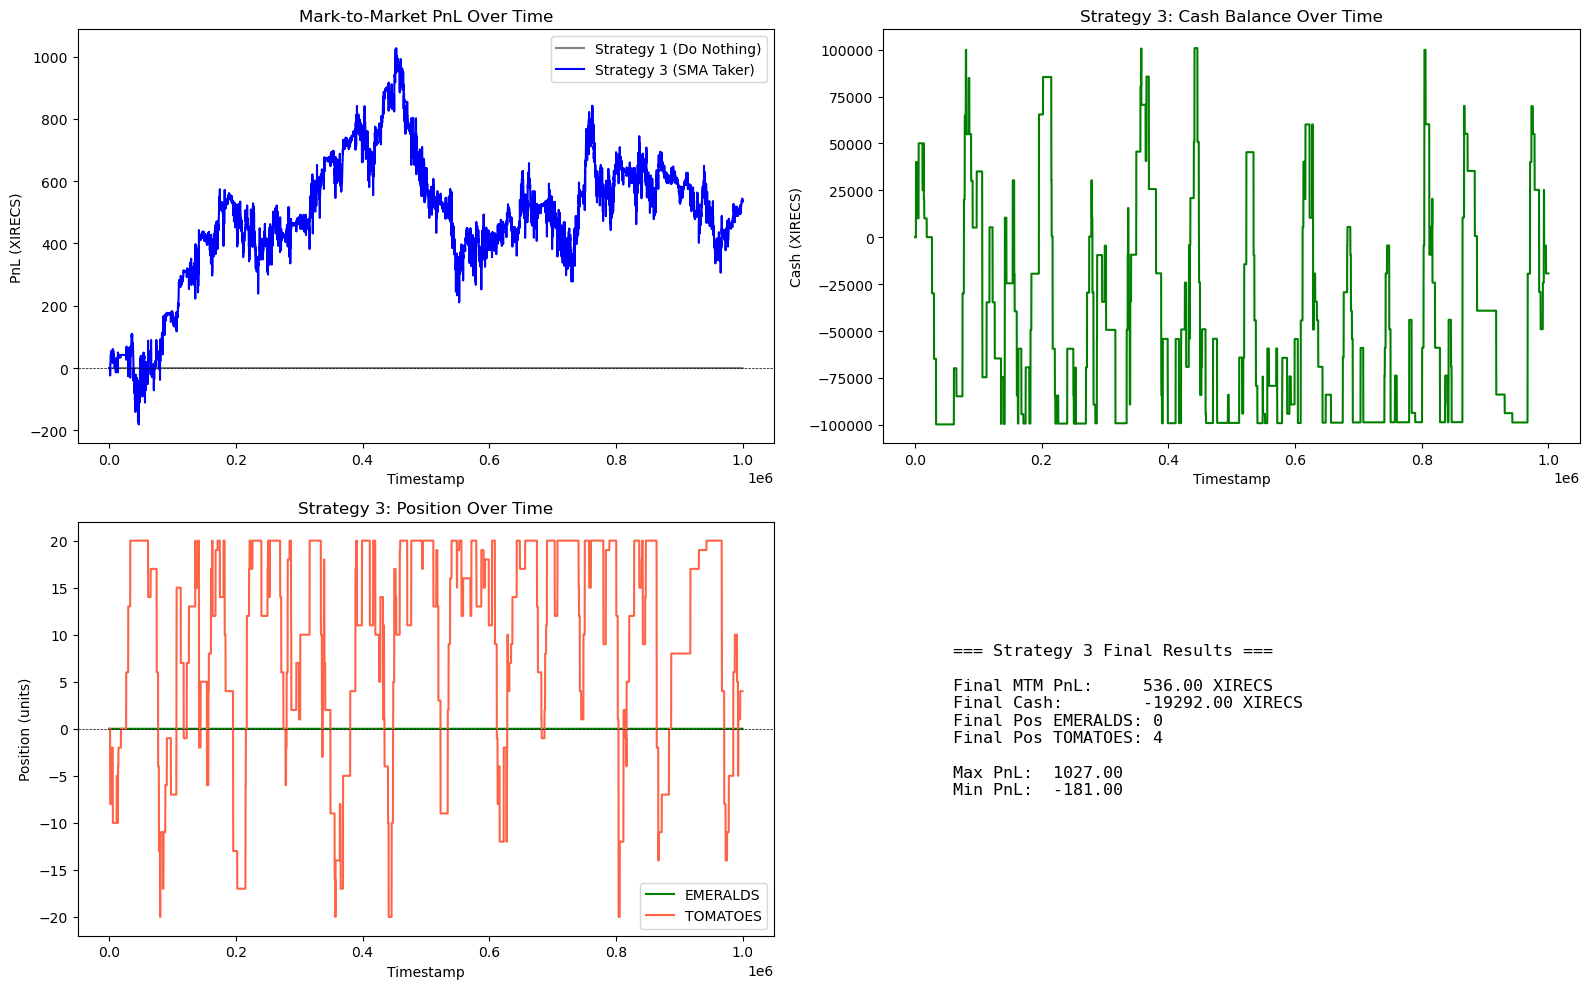

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# PnL curves
axes[0, 0].plot(bt_v1["timestamp"], bt_v1["mtm_pnl"], label="Strategy 1 (Do Nothing)", color="gray")
axes[0, 0].plot(bt_v3["timestamp"], bt_v3["mtm_pnl"], label="Strategy 3 (SMA Taker)", color="blue")
axes[0, 0].set_title("Mark-to-Market PnL Over Time")
axes[0, 0].set_xlabel("Timestamp")
axes[0, 0].set_ylabel("PnL (XIRECS)")
axes[0, 0].legend()
axes[0, 0].axhline(y=0, color="black", linestyle="--", linewidth=0.5)

# Cash
axes[0, 1].plot(bt_v3["timestamp"], bt_v3["cash"], color="green")
axes[0, 1].set_title("Strategy 3: Cash Balance Over Time")
axes[0, 1].set_xlabel("Timestamp")
axes[0, 1].set_ylabel("Cash (XIRECS)")

# Positions
axes[1, 0].plot(bt_v3["timestamp"], bt_v3["pos_EMERALDS"], label="EMERALDS", color="green")
axes[1, 0].plot(bt_v3["timestamp"], bt_v3["pos_TOMATOES"], label="TOMATOES", color="tomato")
axes[1, 0].set_title("Strategy 3: Position Over Time")
axes[1, 0].set_xlabel("Timestamp")
axes[1, 0].set_ylabel("Position (units)")
axes[1, 0].legend()
axes[1, 0].axhline(y=0, color="black", linestyle="--", linewidth=0.5)

# Final stats
axes[1, 1].axis("off")
final = bt_v3.iloc[-1]
stats_text = (
    f"=== Strategy 3 Final Results ===\n\n"
    f"Final MTM PnL:     {final['mtm_pnl']:.2f} XIRECS\n"
    f"Final Cash:        {final['cash']:.2f} XIRECS\n"
    f"Final Pos EMERALDS: {final['pos_EMERALDS']:.0f}\n"
    f"Final Pos TOMATOES: {final['pos_TOMATOES']:.0f}\n\n"
    f"Max PnL:  {bt_v3['mtm_pnl'].max():.2f}\n"
    f"Min PnL:  {bt_v3['mtm_pnl'].min():.2f}\n"
)
axes[1, 1].text(0.1, 0.5, stats_text, transform=axes[1, 1].transAxes,
                fontsize=12, verticalalignment="center", fontfamily="monospace")

plt.tight_layout()
plt.show()

### Backtest on Day -2 (out-of-sample validation)

To confirm the strategy isn't overfit to day -1, let's also run it on the other available sample day.

Running backtest on day -2 data...


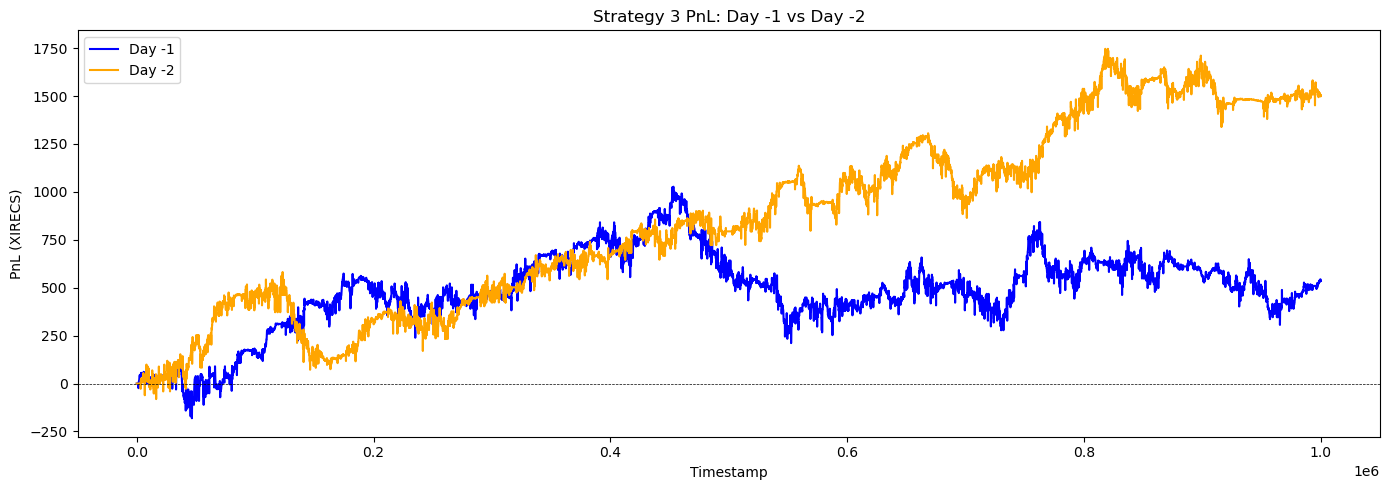

Day -1 final PnL: 536.00
Day -2 final PnL: 1502.00


In [21]:
print("Running backtest on day -2 data...")
bt_v3_d2 = backtest(TraderV3(), "prices_round_0_day_-2.csv", limits)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(bt_v3["timestamp"], bt_v3["mtm_pnl"], label="Day -1", color="blue")
ax.plot(bt_v3_d2["timestamp"], bt_v3_d2["mtm_pnl"], label="Day -2", color="orange")
ax.set_title("Strategy 3 PnL: Day -1 vs Day -2")
ax.set_xlabel("Timestamp")
ax.set_ylabel("PnL (XIRECS)")
ax.legend()
ax.axhline(y=0, color="black", linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.show()

print(f"Day -1 final PnL: {bt_v3.iloc[-1]['mtm_pnl']:.2f}")
print(f"Day -2 final PnL: {bt_v3_d2.iloc[-1]['mtm_pnl']:.2f}")

### New Stratergy

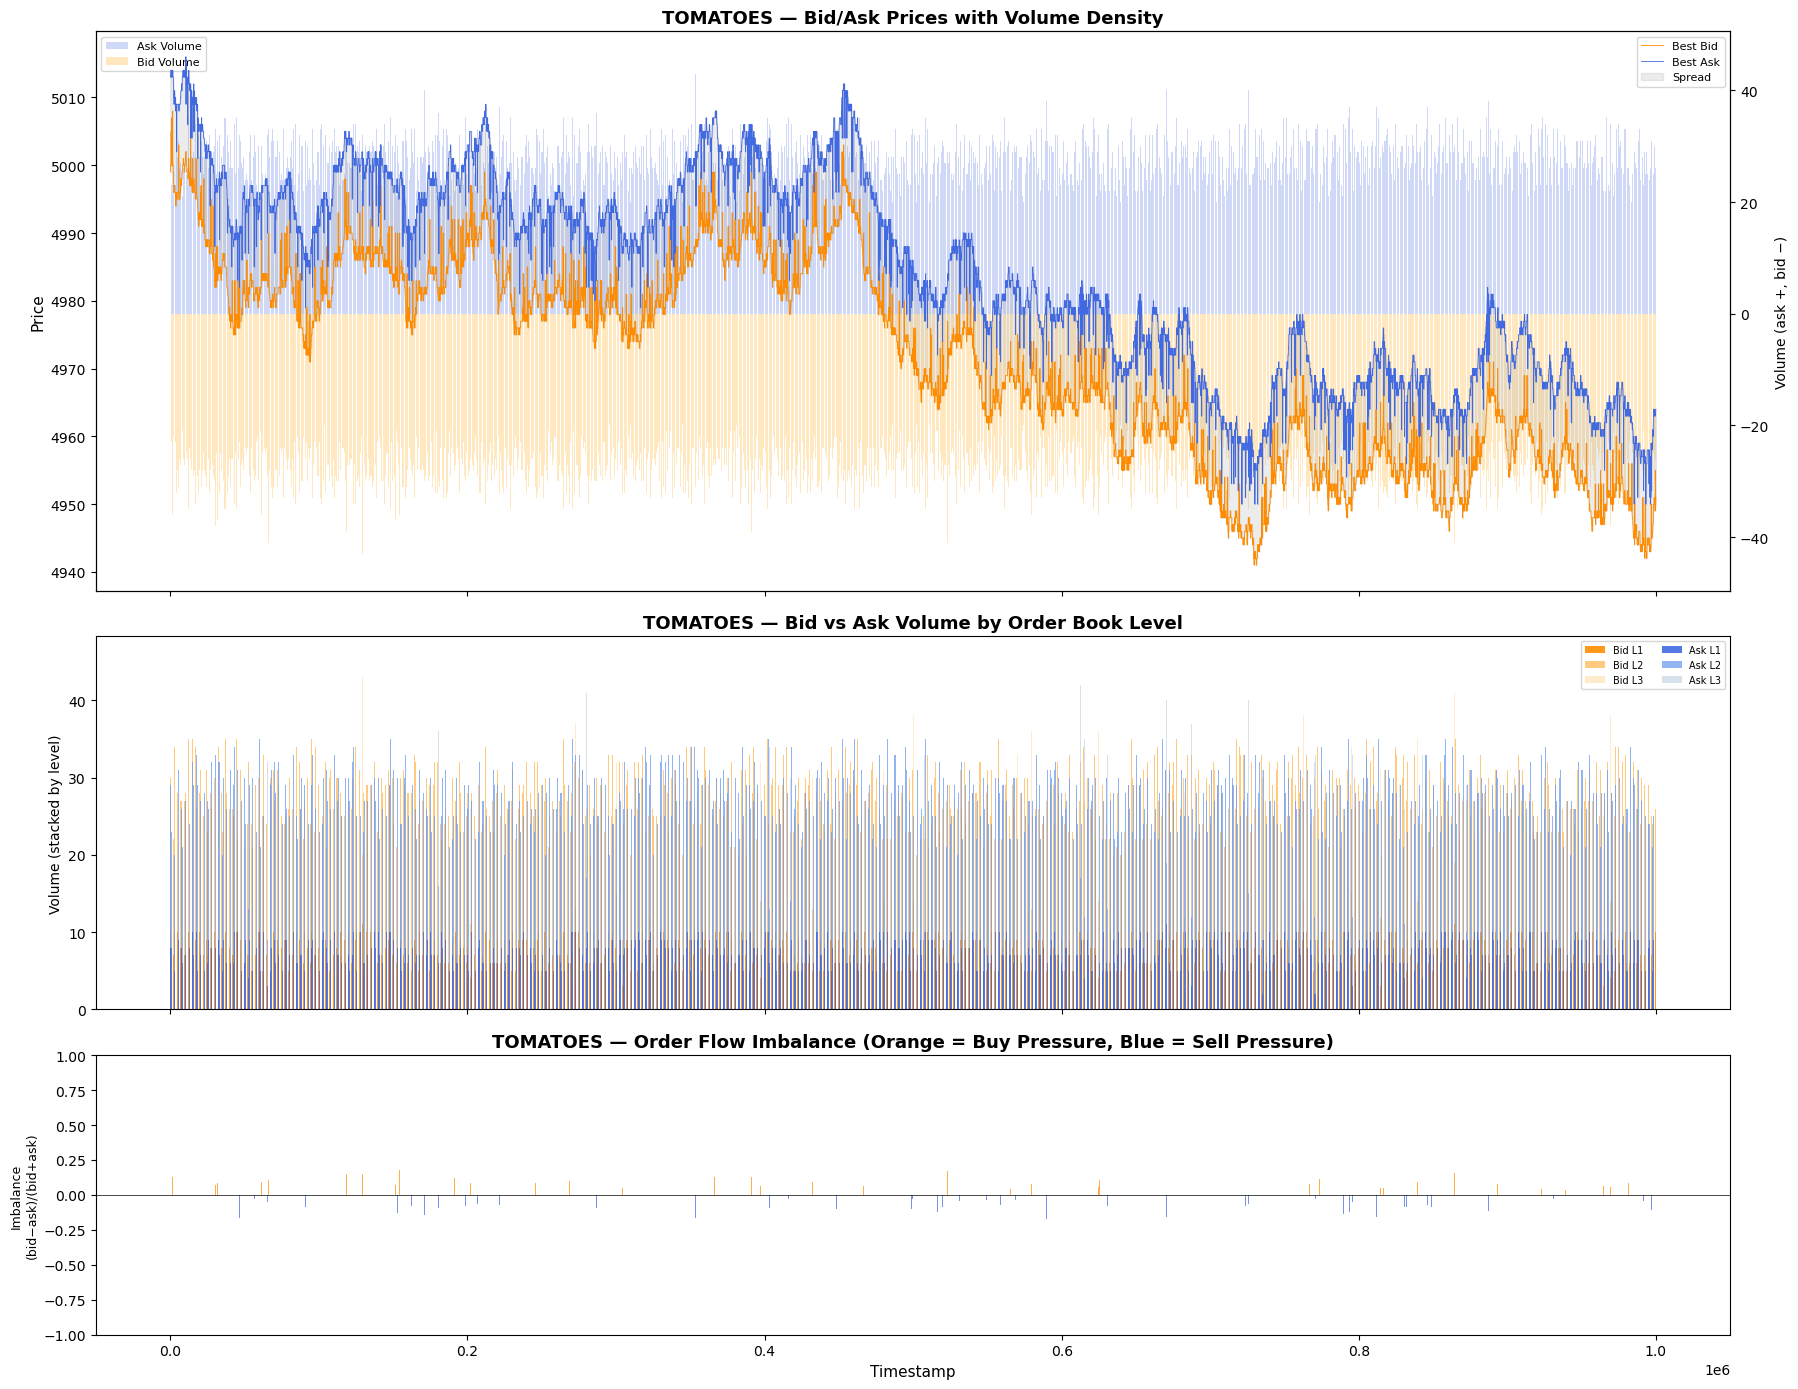

Mean bid volume (all levels): 27.8
Mean ask volume (all levels): 27.8
Mean imbalance: -0.0001  (>0 = net buy pressure, <0 = net sell pressure)
Imbalance std:  0.0270


In [58]:
df = pd.read_csv('prices_round_0_day_-1.csv')
tom_df = df[df['product'] == 'TOMATOES'].copy()

total_bid_vol = tom_df[['bid_volume_1', 'bid_volume_2', 'bid_volume_3']].sum(axis=1)
total_ask_vol = tom_df[['ask_volume_1', 'ask_volume_2', 'ask_volume_3']].sum(axis=1)

fig, (ax_price, ax_vol, ax_imb) = plt.subplots(3, 1, figsize=(18, 14),
                                                 sharex=True,
                                                 gridspec_kw={'height_ratios': [3, 2, 1.5]})
ts = tom_df['timestamp'].values

# --- Panel 1: Bid/Ask prices with volume bars ---
ax_vol_bg = ax_price.twinx()
ax_vol_bg.bar(ts, total_ask_vol, width=80, color='royalblue', alpha=0.25, label='Ask Volume')
ax_vol_bg.bar(ts, -total_bid_vol, width=80, color='orange', alpha=0.25, label='Bid Volume')
ax_vol_bg.set_ylabel('Volume (ask +, bid −)', fontsize=10)
ax_vol_bg.legend(loc='upper left', fontsize=8)

ax_price.plot(ts, tom_df['bid_price_1'], linewidth=0.6, color='darkorange', label='Best Bid')
ax_price.plot(ts, tom_df['ask_price_1'], linewidth=0.6, color='royalblue', label='Best Ask')
ax_price.fill_between(ts, tom_df['bid_price_1'], tom_df['ask_price_1'],
                       color='gray', alpha=0.15, label='Spread')
ax_price.set_ylabel('Price', fontsize=11)
ax_price.set_title('TOMATOES — Bid/Ask Prices with Volume Density', fontsize=13, fontweight='bold')
ax_price.legend(loc='upper right', fontsize=8)
ax_price.set_zorder(ax_vol_bg.get_zorder() + 1)
ax_price.patch.set_visible(False)

# --- Panel 2: Stacked volume bars side-by-side ---
half_w = 40
ax_vol.bar(ts - half_w, tom_df['bid_volume_1'], width=half_w, color='#FF8C00', alpha=0.9, label='Bid L1')
ax_vol.bar(ts - half_w, tom_df['bid_volume_2'], width=half_w, bottom=tom_df['bid_volume_1'],
           color='#FFB347', alpha=0.7, label='Bid L2')
ax_vol.bar(ts - half_w, tom_df['bid_volume_3'].fillna(0), width=half_w,
           bottom=tom_df['bid_volume_1'] + tom_df['bid_volume_2'],
           color='#FFD699', alpha=0.5, label='Bid L3')

ax_vol.bar(ts + half_w, tom_df['ask_volume_1'], width=half_w, color='#4169E1', alpha=0.9, label='Ask L1')
ax_vol.bar(ts + half_w, tom_df['ask_volume_2'], width=half_w, bottom=tom_df['ask_volume_1'],
           color='#6495ED', alpha=0.7, label='Ask L2')
ax_vol.bar(ts + half_w, tom_df['ask_volume_3'].fillna(0), width=half_w,
           bottom=tom_df['ask_volume_1'] + tom_df['ask_volume_2'],
           color='#B0C4DE', alpha=0.5, label='Ask L3')

ax_vol.set_ylabel('Volume (stacked by level)', fontsize=10)
ax_vol.set_title('TOMATOES — Bid vs Ask Volume by Order Book Level', fontsize=13, fontweight='bold')
ax_vol.legend(loc='upper right', ncol=2, fontsize=7)

# --- Panel 3: Order flow imbalance ---
imbalance = (total_bid_vol - total_ask_vol) / (total_bid_vol + total_ask_vol)
colors = np.where(imbalance >= 0, 'darkorange', 'royalblue')
ax_imb.bar(ts, imbalance, width=80, color=colors, alpha=0.7)
ax_imb.axhline(0, color='black', linewidth=0.5)
ax_imb.set_ylabel('Imbalance\n(bid−ask)/(bid+ask)', fontsize=9)
ax_imb.set_xlabel('Timestamp', fontsize=11)
ax_imb.set_title('TOMATOES — Order Flow Imbalance (Orange = Buy Pressure, Blue = Sell Pressure)',
                  fontsize=13, fontweight='bold')
ax_imb.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

print(f"Mean bid volume (all levels): {total_bid_vol.mean():.1f}")
print(f"Mean ask volume (all levels): {total_ask_vol.mean():.1f}")
print(f"Mean imbalance: {imbalance.mean():.4f}  (>0 = net buy pressure, <0 = net sell pressure)")
print(f"Imbalance std:  {imbalance.std():.4f}")

In [ ]:
"""
Next statergy to try is to check for certain inflection points, and creating different support and resistance bands.
create different inflection points and reversion if there are any.

Categories will be upward revert,
downard revert.
down trend.
up trend.
flat trend. ==> Most difficult one to spot on.


First define them all one by one and then start to build that.
"""

'\n'

## New Statergy

In [ ]:
class MomentumTrader:
    def __init__(self, max_points=100, min_points=20,
                 lt_slope_threshold=0.03, st_slope_threshold=0.1):
        self.history = []
        self.resistance_lst = []
        self.support_lst = []
        self.current_trend = None  # -1 (downward), 0 (sideways), 1 (upward)
        self.max_points = max_points
        self.min_points = min_points
        self.lt_slope_threshold = lt_slope_threshold
        self.st_slope_threshold = st_slope_threshold

    def update_history(self, price):
        self.history.append(price)
        if len(self.history) > self.max_points:
            self.history.pop(0)

    def _update_support_resistance(self,support,resistance):
        if support is not None:
            self.support_lst.append(support)
        if resistance is not None:
            self.resistance_lst.append(resistance)  
        
        if len(self.support_lst) > self.min_points:
            self.support_lst.pop(0)
        if len(self.resistance_lst) > self.min_points:
            self.resistance_lst.pop(0)    

    def _get_trend(self, days, threshold):
        """Detect trend direction using least-squares regression slope.

        Fits a line to the last `days` prices. The slope is normalised
        by the standard deviation so the threshold is scale-invariant:
          normalised_slope >  threshold  =>  uptrend   (+1)
          normalised_slope < -threshold  =>  downtrend (-1)
          otherwise                      =>  sideways  ( 0)
        """
        if len(self.history) < days:
            return None

        prices = self.history[-days:]
        n = len(prices)

        x_sum = n * (n - 1) / 2
        x2_sum = n * (n - 1) * (2 * n - 1) / 6
        y_sum = sum(prices)
        xy_sum = sum(i * p for i, p in enumerate(prices))

        denom = n * x2_sum - x_sum * x_sum
        slope = (n * xy_sum - x_sum * y_sum) / denom

        mean = y_sum / n
        std = (sum((p - mean) ** 2 for p in prices) / n) ** 0.5

        if std < 1e-9:
            return 0

        normalised_slope = slope / std

        if normalised_slope > threshold:
            return 1
        elif normalised_slope < -threshold:
            return -1
        return 0
    
    def _get_resistance(self,long_term_trend,short_term_trend):
        if long_term_trend == 1:
            if short_term_trend != -1:
                return None
            
            max_val = max(self.history[-2*self.min_points:])
            return max_val
        return None
    
    def _get_support(self,long_term_trend,short_term_trend):
        if long_term_trend == -1:
            if short_term_trend != 1:
                return None
            
            min_val = min(self.history[-2*self.min_points:])
            return min_val
        return None
    
    def get_action(self,price):
        self.update_history(price)
        self.long_term_trend = self._get_trend(self.max_points//2, self.lt_slope_threshold)
        self.short_term_trend = self._get_trend(self.min_points, self.st_slope_threshold)

        if self.long_term_trend is None or self.short_term_trend is None:
            return "HOLD", None

        # Track the prevailing direction from the long-term trend.
        # Only override when the long-term trend is clearly directional;
        # keep the last known direction during sideways periods so that
        # a subsequent pullback can still trigger a signal.
        if self.long_term_trend != 0:
            self.current_trend = self.long_term_trend

        resistance = self._get_resistance(self.long_term_trend, self.short_term_trend)
        support = self._get_support(self.long_term_trend, self.short_term_trend)

        self._update_support_resistance(support, resistance)

        if resistance is not None and self.current_trend == 1:
            self.current_trend = -1
            return "SELL", resistance

        if support is not None and self.current_trend == -1:
            self.current_trend = 1
            return "BUY", support

        return "HOLD", None

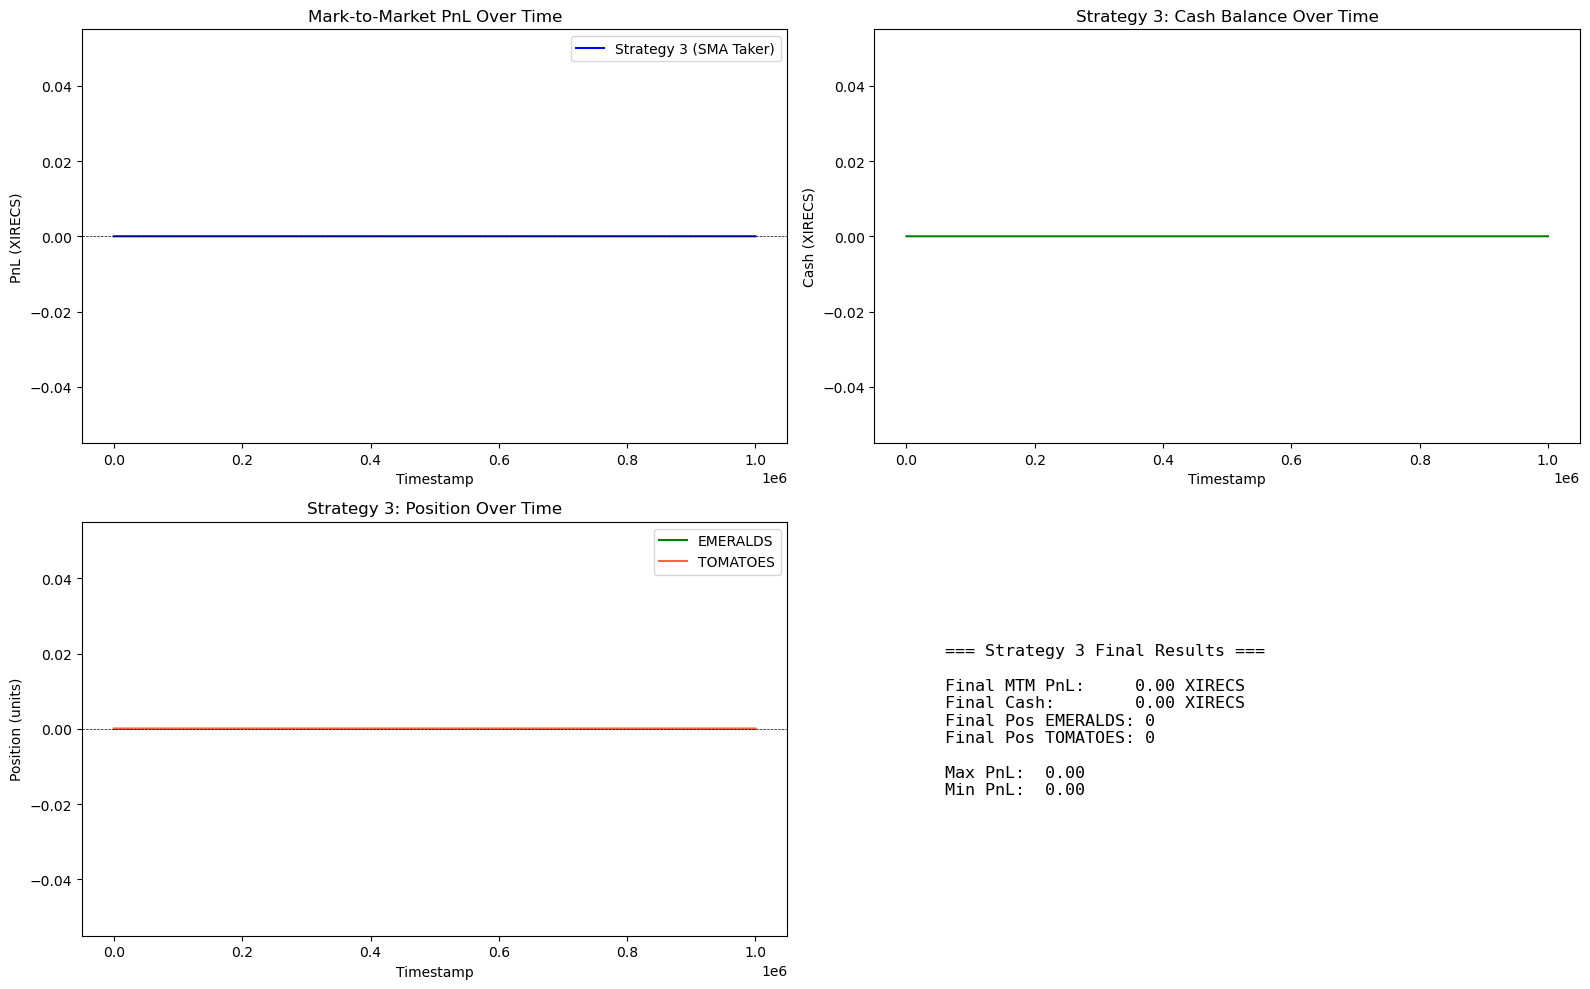

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# PnL curves
axes[0, 0].plot(bt_new["timestamp"], bt_new["mtm_pnl"], label="Strategy 3 (SMA Taker)", color="blue")
axes[0, 0].set_title("Mark-to-Market PnL Over Time")
axes[0, 0].set_xlabel("Timestamp")
axes[0, 0].set_ylabel("PnL (XIRECS)")
axes[0, 0].legend()
axes[0, 0].axhline(y=0, color="black", linestyle="--", linewidth=0.5)

# Cash
axes[0, 1].plot(bt_new["timestamp"], bt_new["cash"], color="green")
axes[0, 1].set_title("Strategy 3: Cash Balance Over Time")
axes[0, 1].set_xlabel("Timestamp")
axes[0, 1].set_ylabel("Cash (XIRECS)")

# Positions
axes[1, 0].plot(bt_new["timestamp"], bt_new["pos_EMERALDS"], label="EMERALDS", color="green")
axes[1, 0].plot(bt_new["timestamp"], bt_new["pos_TOMATOES"], label="TOMATOES", color="tomato")
axes[1, 0].set_title("Strategy 3: Position Over Time")
axes[1, 0].set_xlabel("Timestamp")
axes[1, 0].set_ylabel("Position (units)")
axes[1, 0].legend()
axes[1, 0].axhline(y=0, color="black", linestyle="--", linewidth=0.5)

# Final stats
axes[1, 1].axis("off")
final = bt_new.iloc[-1]
stats_text = (
    f"=== Strategy 3 Final Results ===\n\n"
    f"Final MTM PnL:     {final['mtm_pnl']:.2f} XIRECS\n"
    f"Final Cash:        {final['cash']:.2f} XIRECS\n"
    f"Final Pos EMERALDS: {final['pos_EMERALDS']:.0f}\n"
    f"Final Pos TOMATOES: {final['pos_TOMATOES']:.0f}\n\n"
    f"Max PnL:  {bt_new['mtm_pnl'].max():.2f}\n"
    f"Min PnL:  {bt_new['mtm_pnl'].min():.2f}\n"
)
axes[1, 1].text(0.1, 0.5, stats_text, transform=axes[1, 1].transAxes,
                fontsize=12, verticalalignment="center", fontfamily="monospace")

plt.tight_layout()
plt.show()

---

# Next Steps

Now that you have a working trader and understand every part of the system, here are ideas to improve:

1. **Market making**: Instead of only taking profitable existing orders, also **post your own bids and asks** slightly inside the spread to capture the spread as profit.
2. **Better fair value models**: Use exponential moving average (EMA), VWAP, or regression-based models instead of SMA.
3. **Dynamic position management**: Instead of trading up to the limit, add logic to mean-revert your position toward zero to reduce risk.
4. **Use market_trades signal**: Analyze bot-to-bot trades to detect momentum or mean-reversion signals.
5. **Multi-day analysis**: Compare price patterns across day -1 and day -2 to find recurring patterns.

The submittable `trader.py` file in this directory contains the Strategy 3 logic ready to upload.

In [22]:
import json
with open("28169.json","r") as f:
    data = json.load(f)

print(data)


{'round': '0', 'status': 'FINISHED', 'profit': 76.15625, 'activitiesLog': 'day;timestamp;product;bid_price_1;bid_volume_1;bid_price_2;bid_volume_2;bid_price_3;bid_volume_3;ask_price_1;ask_volume_1;ask_price_2;ask_volume_2;ask_price_3;ask_volume_3;mid_price;profit_and_loss\n-1;0;TOMATOES;4999;6;4998;19;;;5013;6;5014;19;;;5006.0;0.0\n-1;0;EMERALDS;9992;15;9990;30;;;10008;15;10010;30;;;10000.0;0.0\n-1;100;EMERALDS;9992;13;9990;30;;;10008;13;10010;30;;;10000.0;0.0\n-1;100;TOMATOES;5000;5;4998;23;;;5013;5;5014;23;;;5006.5;0.0\n-1;200;EMERALDS;9992;13;9990;21;;;10008;13;10010;21;;;10000.0;0.0\n-1;200;TOMATOES;5000;10;4999;20;;;5013;10;5015;20;;;5006.5;0.0\n-1;300;TOMATOES;5000;9;4999;24;;;5014;9;5015;24;;;5007.0;0.0\n-1;300;EMERALDS;9992;11;9990;23;;;10008;11;10010;23;;;10000.0;0.0\n-1;400;TOMATOES;5000;6;4999;25;;;5014;6;5015;25;;;5007.0;0.0\n-1;400;EMERALDS;9992;13;9990;23;;;10008;13;10010;23;;;10000.0;0.0\n-1;500;EMERALDS;9992;12;9990;22;;;10008;12;10010;22;;;10000.0;0.0\n-1;500;TOMATOES;